# Artificial Intelligence - Lecture 01
## Introduction and Uninformed Search


## Why Study AI?

### What is Artificial intelligence?
Field of computer science which strives to replicate the human thinking process or to be strong in fields where the humans dominate.


### What you will gain from the course
- **Strengthen programming skills and algorithmic thinking.**
- **A highly relevant field**: AI is shaping modern technology and is becoming increasingly important across industries.
- **Learn practical, real-world algorithms** - explore techniques that are not only academically interesting but are widely used in real applications.
- **Become a stronger specialist** - combine theory with practical problem-solving skills that can set you apart as a developer or engineer.


## Curriculum

- Introduction
- Uninformed Search (+ Introduction)
- Informed Search (+ Local Search)
- Constraint Satisfaction Problems
- Genetic Algorithms
- Adversarial Search (Games)
- Introduction to Machine Learning
- kNN
- Naive Bayes Classifier
- Decision Trees
- Clustering
- Neural Networks

## What could we solve after the first part of the course?

Consider the following problems:

1. **Predict the price of a property from its characteristics**.
2. **Find a short route from point A to point B in a complicated urban environment**.
3. **Build a strong chess-playing bot**.
4. **Plan deliveries so that a courier can serve many customers while travelling as little as possible**.
5. **Automatically construct a schedule with multiple constraints and complex resource allocation**


## A Problem as a State-Space Search

Before discussing search algorithms, we need a precise representation of the problem.

### State

A **state** describes the current configuration of the objects relevant to the problem.

We commonly distinguish between:

- **Initial state** — the state where the search starts, often denoted by `S`.
- **Intermediate state** — any state reached while solving the problem.
- **Goal state** — a state satisfying the desired condition, often denoted by `G`.

### Successor Function

The **successor function** (or **operator**) describes how one state can be transformed into another.

> **Successor function = obtaining one state from another by applying an allowed action.**

### Solution

A **solution** is a sequence of actions that takes us from the **initial state** to a **goal state**.

### Path Cost

The **path cost** is the accumulated cost of the actions taken along a path.

Examples include:

- **Total distance** travelled
- **Number of actions**
- **Total time**
- **Monetary cost**

---

## State Space and Search Trees

The **state space** is the collection of all states that can be reached from the initial state using the available actions.

A useful mental model is a **graph**:

- Each **state** is a node.
- Each valid transition is an edge.
- The **successor function** determines which edges can be followed.

A search procedure may also construct a **search tree** while exploring the state space.

In this representation:

- The **initial state** is the root.
- Generated states form the nodes.
- Terminal states and goal states can appear as **leaves**.

### Important Distinction

The underlying problem can be represented as a **graph**, while a particular search process can be viewed as exploring a **tree of generated paths**.

This distinction becomes important when the **same state can be reached through multiple paths**.

---

## Parameters Used to Describe a Search Problem

Several quantities will appear repeatedly when we analyze search algorithms.

| Symbol / Term | Meaning |
|---|---|
| `b` | **Maximum branching factor** — the largest number of successors of a node |
| `d` | **Depth of the least-cost solution** |
| `m` | **Maximum depth of the search space**; it may be infinite |
| Path cost | **Total cost** accumulated along a path |
| Completeness | Whether the strategy **finds a solution whenever one exists** |
| Optimality | Whether the strategy **finds a least-cost solution** |
| Time complexity | How many nodes may need to be **generated or expanded** |
| Space complexity | How many nodes may need to be **stored in memory** |

For time and space analysis, we are usually interested in the **worst case**.

---

## Two Ways to Think About Search

### Global Search

A **global search** strategy keeps information about the broader search process:

- Where it has already been
- What has been visited
- What remains to be explored
- Potentially, information about the search space

### Local Search

**Local search** concentrates on the **current state and its nearby alternatives**.

The algorithm repeatedly moves from one candidate solution to another using local changes.

A typical example is **hill climbing**:

> If we want to climb to the highest point, repeatedly choose a nearby position that improves the current value.

Local search is particularly useful when we care primarily about the **final solution** rather than the exact path used to reach it.

## Informed vs. Uninformed Search

Another important distinction is whether the algorithm has additional information about where a solution is likely to be.

### Informed search

An informed strategy uses some estimate or heuristic about the remaining problem.

For example, we might have a function estimating the distance from the current state to a goal.

### Uninformed search

An **uninformed (blind) search** does not have such guidance.

It uses only the information contained in the formal problem definition:

- the initial state,
- the available actions,
- the successor function,
- the goal test,
- and path costs where applicable.

The algorithms in this lecture are, they are **Uninformed and Global** search strategies

- **Depth-First Search (DFS)**
- **Breadth-First Search (BFS)**
- **Uniform-Cost Search (UCS)**
- **Depth-Limited Search (DLS)**
- **Iterative Deepening Search (IDS)**


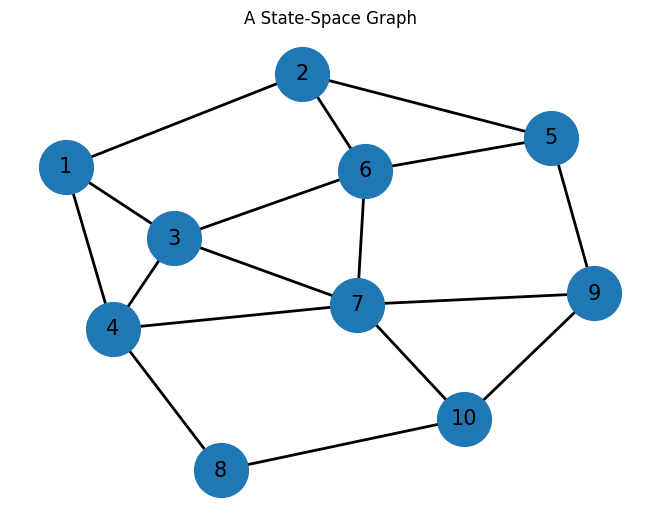

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()

G.add_nodes_from(range(1, 11))

G.add_edges_from([
    (1, 2),
    (1, 3),
    (1, 4),

    (2, 5),
    (2, 6),

    (3, 4),
    (3, 6),
    (3, 7),

    (4, 7),
    (4, 8),

    (5, 9),
    (6, 5),
    (6, 7),

    (7, 9),
    (7, 10),

    (8, 10),

    (9, 10)
])

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1500,
    font_size=15,
    width=2
)

plt.title("A State-Space Graph")
plt.show()

### Interactive question

Assume:

- node `1` is the start,
- node `5` is the goal.

Without running any algorithm:

1. What could DFS visit first?
2. What would BFS prioritize?


# Depth-First Search (DFS)

## The basic idea

**Go deep first.**

DFS follows one branch as far as possible before backtracking and trying another branch.

A useful analogy is exploring a maze:

> Keep following the current corridor until you reach a dead end; then return to the most recent choice point.

### Core data structure

DFS naturally uses a **stack**.

The most recently discovered node is processed first.

### Important consequence

DFS can reach a deep branch very quickly, even if a much shallower solution exists elsewhere.


### DFS - evaluation

**Completeness:** No in general.

DFS can fail to find a solution in an infinite-depth search space even when a solution exists.

For example, imagine the operations:

- `x → x - 1`
- `x → 2x`

Start at `5` and search for `10`.

If the algorithm repeatedly chooses multiplication, it can produce:

`5 → 10 → 20 → 40 → 80 → ...`

In a suitable infinite search space, a branch like this can prevent DFS from reaching another branch containing the solution.

A practical restriction such as returning when the current value exceeds the target can prevent this particular trap, but it is a problem-specific rule rather than a general property of DFS.

**Optimality:** No.

DFS does not generally guarantee the least-cost solution.

**Time complexity:** `O(b^m)`

In the worst case, the goal may be the last node encountered, requiring exploration of nodes across depths up to `m`.

**Space complexity:** `O(bm)`

DFS mainly stores:

- the current path: `O(m)`
- frontier alternatives along that path: up to approximately `O(bm)`

### Data structure

**Stack**


In [3]:
visited = set()
graph = G
goal = 10

def dfs(current):
    visited.add(current)

    if current == goal:
        return [current]

    for neighbor in graph.neighbors(current):
        if neighbor not in visited:
            path = dfs(neighbor)

            # Backtracking
            if path is not None:
                return [current] + path

    return None

path = dfs(current=1)

print("DFS path:", path)

DFS path: [1, 2, 5, 9, 7, 3, 4, 8, 10]


# Breadth-First Search (BFS)

## The basic idea

**Explore level by level.**

BFS first examines all nodes at depth 1, then all nodes at depth 2, then depth 3, and so on.

### Core data structure

BFS naturally uses a **queue**:

> First discovered → first processed.

This is the opposite exploration order from a stack-based DFS.


### BFS - evaluation

**Completeness:** Yes, under the standard assumption of a finite branching factor.

**Optimality:** Yes when every action has the same cost (for example, cost `1` per step).

It is not generally optimal when different actions have different costs.

**Time complexity:** `O(b^(d+1))`

In the worst case, BFS may generate all nodes through the solution depth and may also generate successors of nodes at that level.

**Space complexity:** `O(b^(d+1))`

This is one of the major disadvantages of BFS: it can keep a very large frontier in memory.

### Data structure

**Queue**


## DFS vs. BFS - one question

Suppose the goal is very shallow, but the search tree is extremely wide.

Which strategy has a natural reason to reach the goal quickly?

Now change the situation:

> The goal is deep, and the tree has many shallow branches.

Which strategy may consume much more memory?

The point is not to memorize a winner. The important idea is that **the structure of the search space interacts with the exploration strategy**.


In [ ]:
from collections import deque


def bfs(graph, start, goal):
    visited = set()
    queue = deque([start])

    while queue:
        current = queue.popleft()

        if current in visited:
            continue

        visited.add(current)

        print(current)

        if current == goal:
            return True

        for neighbor in graph.neighbors(current):
            if neighbor not in visited:
                queue.append(neighbor)

    return False


# Example
bfs(G, start=1, goal=10)

1
2
3
4
5
6
7
8
9
10


True

# Uniform-Cost Search (UCS)

Used for finding an optimal path from a start to a goal state. Similar to the Dijkstra algorithm, but it stops when it reaches the goal state, while Dijkstra finds the optimal path to all nodes.

### Core idea

**Uniform-Cost Search always expands the frontier node with the lowest path cost from the start.**

The frontier is naturally represented by a **priority queue**, usually implemented with a heap.

The priority of a node is its accumulated path cost from the start.


### UCS - evaluation

Let:

- `C*` be the optimal solution cost,
- `ε` be the minimum positive step cost.

**Completeness:** Yes, under the usual assumptions, including non-negative costs and appropriate conditions on positive step costs.

**Optimality:** Yes for non-negative edge costs.

The key reason is simple:

> UCS explores paths in increasing order of accumulated cost.

UCS is closely related to **Dijkstra's algorithm**. The main conceptual difference is that UCS is formulated as a search procedure that stops when a goal is selected for expansion, while Dijkstra's algorithm is typically described as computing shortest paths to all reachable vertices (or until a desired target is settled).

**Time complexity:** `O(b^(1 + ceil(C*/ε)))`

**Space complexity:** `O(b^(1 + ceil(C*/ε)))`

The important lesson is that, unlike BFS, UCS is driven by **cost**, not depth.

### Data structure

**Priority queue**


In [ ]:
import heapq


def uniform_cost_search(graph, start, goal):
    frontier = [(0, start)]  # (cost, node)
    best_cost = {start: 0}

    while frontier:
        cost, node = heapq.heappop(frontier)

        if node == goal:
            return cost

        if cost > best_cost[node]:
            continue

        for neighbor, edge_cost in graph[node]:
            new_cost = cost + edge_cost

            if neighbor not in best_cost or new_cost < best_cost[neighbor]:
                best_cost[neighbor] = new_cost
                heapq.heappush(frontier, (new_cost, neighbor))

    return None

# Depth-Limited Search (DLS)

Depth-Limited Search can be viewed as:

> **DFS + a maximum allowed depth `l`**

Nodes at depth `l` are not expanded further.

This gives us a simple way to prevent DFS from descending indefinitely.

**It is typically not used standalone**, but as a part of another algorithm as we will see more

### What do we gain?

- It avoids exploring arbitrarily deep branches.
- It keeps the memory characteristics of depth-first exploration.
- It introduces a new issue: the depth limit might be too small.

If the solution is at depth 5 and we choose `l = 3`, DLS cannot reach it.

**Time complexity:** `O(b^l)`

**Space complexity:** `O(bl)`

### Data structure

**Stack**

In [ ]:

goal = 10
graph = G
l = 3

def dfs(current, level):
    visited.add(current)

    if level > l:
        return None

    if current == goal:
        return [current]

    for neighbor in graph.neighbors(current):
        if neighbor not in visited:
            path = dfs(neighbor, level + 1)

            if path is not None:
                return [current] + path

    return None


# Iterative Deepening Search (IDS)

DLS gives us a depth limit.

IDS asks:

> What if we do not know the correct limit?

The answer is to repeatedly run DLS with increasing limits:

`l = 0, 1, 2, 3, ...`

until a solution is found.

So IDS combines improves massively both DFS and BFS


### IDS - evaluation

**Completeness:** Yes under the standard finite-branching assumptions.

**Optimality:** Yes when every step has the same cost.

The reason is that the sequence of depth limits effectively discovers the shallowest solution first, similar to BFS.

**Time complexity:** `O(b^d)`

The repeated work is:

`b^0 + (b^0 + b^1) + (b^0 + b^1 + b^2) + ... + (b^0 + b^1 + ... + b^d)`

which can be written as:

`(d+1)b^0 + db^1 + ... + b^d`, the magnitude of the `b^d` is bigger than the whole sum before.

and is `O(b^d)`.

**Space complexity:** `O(bd)`

IDS repeatedly performs depth-first searches, so it does not keep the entire breadth-first frontier in memory.

### Data structure

**Stack**


# IDS vs. BFS

Consider:

- `b = 10`
- `d = 5`
- the solution is the far-right leaf at depth 5.

For BFS, the number of generated nodes can be represented by:

`b^0 + b^1 + ... + b^d + b(b^d - 1)` which is `O(b^(d+1))`

For IDS, repeated depth-limited searches give:

`(d+1)b^0 + db^1 + ... + b^d` which is `O(b^d)`

For these values:

`N_IDS = 6 + 10·5 + 4·100 + 3·1000 + 2·10^4 + 10^5 = 123,456`

while:

`N_BFS = 1 + 10 + 100 + 1,000 + 10,000 + 100,000 + 999,990 = 1,111,101`

### Why can IDS be attractive?

IDS repeats work at the upper levels, but it does **not expand all nodes at depth `d`** before testing the goal in the same way as the described BFS procedure.

A possible implementation can also apply the goal test when a node is generated, changing the exact accounting.

The broader lesson is:

> Repeating a small amount of shallow work can be cheaper than storing and expanding a huge frontier.


# Algorithm Comparison

The following table collects the main properties discussed in the lecture.

| Algorithm | Complete | Optimal | Time | Space | Main data structure |
|---|---|---|---|---|---|
| DFS | No in general | No | `O(b^m)` | `O(bm)` | Stack |
| BFS | Yes, under standard finite-branching assumptions | Yes if step costs are equal | `O(b^(d+1))` | `O(b^(d+1))` | Queue |
| UCS | Yes under standard non-negative-cost assumptions | Yes for non-negative costs | `O(b^ceil(C*/ε))` | `O(b^ceil(C*/ε))` | Priority queue |
| DLS | Yes if `l ≥ d` and standard assumptions hold | No in general | `O(b^l)` | `O(bl)` | Stack |
| IDS | Yes under standard finite-branching assumptions | Yes if step costs are equal | `O(b^d)` | `O(bd)` | Stack |

### A better way to remember the table

Do not memorize five rows independently.

Remember the mechanism:

- **DFS → stack → go deep**
- **BFS → queue → go level by level**
- **UCS → priority queue → cheapest path first**
- **DLS → DFS with a depth limit**
- **IDS → DLS with an increasing limit**


# Frog Leap Puzzle - Exercise

Use a small **Frog Leap** puzzle as the practical exercise for this lecture.

The goal is to formulate the puzzle as a search problem:

1. Define the **state**.
2. Define the **initial state**.
3. Define the **goal state**.
4. Define the **successor function**.
5. Decide what the **path cost** should be.
6. Identify a suitable uninformed search strategy.
7. Compare the behaviour of two strategies.

### Homework

Implement a solver for the puzzle using at least one uninformed search strategy.

Then try another strategy and compare:

- number of explored states,
- solution length,
- execution time,
- memory usage if you choose to measure it.


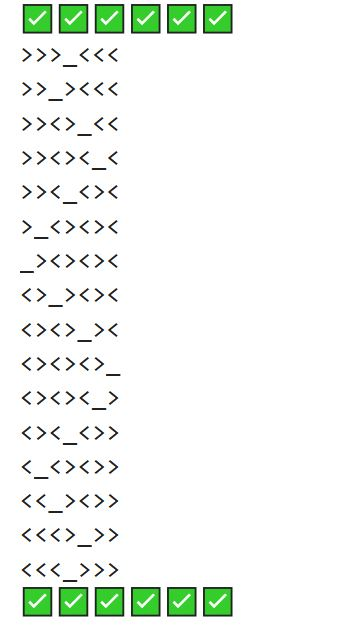

# What concepts you should know

### Problem representation
- State
- Successor function
- State space
- Solution
- Path cost

### Types of search algorithms
- Informed vs Uninformed search
- Global vs Local search

### Evaluation

Every strategy should be examined through:

- **Completeness**
- **Optimality**
- **Time complexity**
- **Space complexity**


### Search algorithms and their characteristics

- DFS
- BFS
- UCS
- DLS
- IDS


# (Optional) Related Algorithms

Once the basic strategies are understood, several related ideas become interesting.

### Bidirectional Search

Instead of searching only from the initial state toward the goal, search can proceed from **both ends**.

For suitable problems, two smaller searches can meet in the middle.

Possible variants include:

- Bidirectional BFS
- Bidirectional shortest-path methods

### Bellman–Ford

Bellman–Ford is another shortest-path algorithm worth knowing.

It differs from Dijkstra/UCS in important ways, particularly in its handling of negative edge weights.

These algorithms are useful follow-up topics because they show that changing the assumptions about the problem can require changing the search strategy.
